## **Modelo de Redes Neurais**

### **Configuração da pasta raiz**

In [1]:
from pathlib import Path

DATASET = Path("data/00_final_dataset.csv")
for pasta in (Path.cwd(), *Path.cwd().parents):
    caminho_dados = pasta / DATASET
    if caminho_dados.is_file():
        break
else:
    raise FileNotFoundError(
        f"Arquivo {DATASET} não encontrado. Abra o notebook na pasta notebooks do projeto."
    )

### **Bibliotecas**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
    log_loss, classification_report, ConfusionMatrixDisplay, cohen_kappa_score,
    mean_absolute_error, roc_curve, precision_recall_curve, average_precision_score,
)
import time
from sklearn.calibration import calibration_curve                                 # Curva de calibração
from sklearn.metrics import brier_score_loss                                      # Escore de Brier
import shap
from sklearn.dummy import DummyClassifier
from matplotlib.patches import Ellipse


### **Leitura da base de dados**

In [3]:
dados = pd.read_csv(caminho_dados)

### **Etapa 1: Especificação de variáveis**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [4]:
# Variáveis explicativas quantitativas
lista_X_quanti = [
  # Informações Físicas e do Draft
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # Estatísticas Avançadas (Eficiência)
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # Estatísticas de Arremesso (Volume e Precisão)
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # Estatísticas tradicionais (por 40 minutos)
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # Experiência no College (Acumulados)
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas
lista_X_quali = [
    'college_name', 
    'conference', 
    'position'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [5]:
y = dados['target_label']
X = dados[lista_X_quali + lista_X_quanti]

In [6]:
# Ordenando as categorias da resposta y
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))
if y.isna().any():
    raise ValueError("target_label contém valores ausentes ou fora das quatro classes esperadas.")

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [7]:
# Divisão em treino / validação / teste
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=123, stratify=y
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15, random_state=123, stratify=y_temp
)


*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [8]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_val = y_val.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [9]:
y_treino.value_counts()

target_label
0    337
1    188
2     87
3     36
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [10]:
preprocessador = ColumnTransformer(transformers=[
    ("quanti", StandardScaler(), lista_X_quanti),
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="passthrough"
)

*Criação do pré-processamento no conjunto de treino* <br>

In [11]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # Ajusta o pré-processamento apenas no conjunto de treino.
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [12]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,-0.078427,0.330030,0.162617,0.512335,1.716687,0.840024,0.409205,-0.129173,-0.308609,-0.581788,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.087953,1.033513,1.033491,-0.010077,-0.844706,-1.050273,1.071529,0.688902,0.248186,1.154490,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.088199,-0.373454,-0.708257,0.564576,0.557961,1.225084,-0.530868,-0.054802,0.070012,0.097625,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-1.411434,1.033513,1.033491,1.557160,0.326216,0.349947,-0.530868,-0.184951,0.871796,-0.430808,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.921328,-0.373454,0.162617,-0.532490,1.326379,1.085062,0.152821,0.912013,0.582263,-0.732769,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [13]:
X_teste_tratada = preprocessador.transform(X_teste)  
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,-0.411679,0.330030,1.033491,0.198888,0.009091,-0.603953,-0.338581,-0.705544,-1.778546,-0.430808,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.254824,-1.780422,-1.579131,-1.472832,-0.064091,0.656245,-0.146293,-0.556803,-0.798588,0.324096,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.578305,0.330030,1.033491,0.930265,-0.686144,-0.682715,-0.509503,-0.352284,-0.330880,-0.657279,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.421205,1.033513,1.033491,0.355611,-0.381216,-0.463931,0.558762,0.298457,-1.489013,0.173115,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-1.244808,0.330030,1.033491,1.557160,0.094471,-0.210141,2.075697,1.711496,-0.085891,1.682922,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


*Aplicação do pré-processamento no conjunto de validação*

In [14]:
X_val_tratada = preprocessador.transform(X_val)  
X_val_tratada = pd.DataFrame(X_val_tratada, columns=nomes_variaveis)
X_val_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,-0.078427,0.330030,0.162617,-0.950420,0.936072,0.778764,0.409205,0.391420,-0.954490,0.022135,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.078427,0.330030,0.162617,1.557160,0.704327,2.529038,0.451935,0.633124,0.715894,-1.034730,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.421205,0.330030,0.162617,0.825782,-1.613124,-1.925410,0.686953,0.819050,-0.330880,0.928019,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.588076,1.033513,1.033491,-1.159384,0.094471,0.069903,1.434739,1.153717,2.675811,2.513316,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.078182,0.330030,1.033491,1.557160,-0.991072,-0.245146,-1.065000,-1.300507,-1.114847,-1.110221,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


*Padroniza X como float32 e y como int32 para o Keras.*

In [15]:
X_treino_tratada = np.asarray(X_treino_tratada, dtype=np.float32)
X_val_tratada    = np.asarray(X_val_tratada,    dtype=np.float32)
X_teste_tratada  = np.asarray(X_teste_tratada,  dtype=np.float32)

y_treino = np.asarray(y_treino, dtype=np.int32)
y_val    = np.asarray(y_val,    dtype=np.int32)
y_teste  = np.asarray(y_teste,  dtype=np.int32)

*Divisão de treino, validação e teste*

In [16]:
print(f"Treino: {X_treino_tratada.shape} | Validação: {X_val_tratada.shape} | Teste externo: {X_teste_tratada.shape}")
print(f"Entradas da rede após o pré-processamento: {X_treino_tratada.shape[1]} "
      f"({len(lista_X_quanti)} quantitativas + {X_treino_tratada.shape[1] - len(lista_X_quanti)} dummies de {len(lista_X_quali)} variáveis qualitativas)")

Treino: (648, 65) | Validação: (115, 65) | Teste externo: (191, 65)
Entradas da rede após o pré-processamento: 65 (33 quantitativas + 32 dummies de 3 variáveis qualitativas)


*Ajusta o balanceamento da base de treino*

In [17]:
classes = np.unique(y_treino)
weights = compute_class_weight('balanced', classes=classes, y=y_treino)
class_weight = dict(zip(classes, weights))
display(pd.DataFrame({'classe': ordem_categorias, 'n_treino': np.bincount(y_treino),
    'proporcao': (np.bincount(y_treino) / len(y_treino)).round(3), 'peso_na_perda': np.round(weights, 3)}))

# Referência: cross-entropy das probabilidades iguais às proporções de classe no treino.
prior_treino = np.bincount(y_treino, minlength=len(classes)) / len(y_treino)
ce_prior_val = log_loss(y_val, np.tile(prior_treino, (len(y_val), 1)), labels=classes)
print(f"Cross-entropy de referência (prever só a prevalência do treino) na validação: {ce_prior_val:.3f}")

,classe,n_treino,proporcao,peso_na_perda
0,Bust,337,0.520,0.481
1,Rotation,188,0.290,0.862
2,Starter,87,0.134,1.862
3,Star,36,0.056,4.500


Cross-entropy de referência (prever só a prevalência do treino) na validação: 1.126


### **Etapa 4: Definição das arquiteturas e hiperparâmetros**

*Parâmetros de entrada dos modelos*

In [18]:
CONFIGS = {
    'Compacta_32_16': dict(widths=(32,16), drops=(.1,.1), lr=.001, batch=16),
    'Intermediaria_64_32': dict(widths=(64,32), drops=(.2,.2), lr=.001, batch=16),
    'Ampla_128_64': dict(widths=(128,64), drops=(.2,.2), lr=.001, batch=32),
    'Intermediaria_sem_dropout': dict(widths=(64,32), drops=(0.,0.), lr=.001, batch=32)
}
SEEDS = [123, 7, 42, 2024, 99] 
SEMENTE_TESTE = SEEDS[0]

*Arquiteturas utilizadas*

In [27]:
def desenhar_arquitetura(nome, salvar=False):
    cfg = CONFIGS[nome]
    n_entrada = X_treino_tratada.shape[1]
    MAX_VIS = 10

    camadas = [(n_entrada, '#3498db', 'Entrada', f'{n_entrada} variáveis\n(padronizadas + one-hot)')]
    for k, (largura, drop) in enumerate(zip(cfg['widths'], cfg['drops']), start=1):
        texto = f'{largura} neurônios\nReLU' + (f' + Dropout {drop:.1f}' if drop > 0 else ' (sem Dropout)')
        camadas.append((largura, '#9b59b6', f'Oculta {k}', texto))
    camadas.append((len(ordem_categorias), '#27ae60', 'Saída', f'{len(ordem_categorias)} neurônios\nsoftmax'))

    # Calcula o número de pesos e vieses das camadas densas.
    n_param = 0
    for i in range(len(camadas) - 1):
        n_in  = camadas[i][0]
        n_out = camadas[i + 1][0]
        n_param += n_in * n_out + n_out   # pesos + bias

    xs = np.linspace(0.08, 0.86, len(camadas))
    largura_fig, altura_fig = 13, 6
    fig, ax = plt.subplots(figsize=(largura_fig, altura_fig))

    posicoes_camadas = []
    for x, (n_real, cor, titulo, label) in zip(xs, camadas):
        posicoes_camadas.append([(x, y) for y in np.linspace(0.85, 0.15, min(n_real, MAX_VIS))])

    for i in range(len(camadas) - 1):
        for p1 in posicoes_camadas[i]:
            for p2 in posicoes_camadas[i + 1]:
                ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='#bdc3c7', linewidth=0.35, alpha=0.4, zorder=1)

    for (x, (n_real, cor, titulo, label)), poss in zip(zip(xs, camadas), posicoes_camadas):
        for px, py in poss:
            ax.add_patch(Ellipse((px, py), 0.044 * altura_fig / largura_fig, 0.044, color=cor, ec='white', lw=1.2, zorder=2))
        if n_real > MAX_VIS:
            ax.text(x, 0.085, '⋮', ha='center', va='center', fontsize=16, color=cor)
        ax.text(x, 0.98, titulo, ha='center', fontsize=11, fontweight='bold', color=cor)
        ax.text(x, 0.01, label, ha='center', va='bottom', fontsize=9, color='#2c3e50')

    for (px, py), nome_classe in zip(posicoes_camadas[-1], ordem_categorias):
        ax.text(px + 0.035, py, nome_classe, va='center', fontsize=10, color='#27ae60', fontweight='bold')

    for i in range(len(camadas) - 1):
        ax.annotate('', xy=(xs[i + 1] - 0.05, 0.5), xytext=(xs[i] + 0.05, 0.5),
                    arrowprops=dict(arrowstyle='->', lw=1.5, color='#34495e', alpha=0.7))

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis('off')
    ax.set_title(f'Arquitetura do MLP ({nome}): ' + ' → '.join(str(c[0]) for c in camadas)
                 + f'  |  {n_param} parâmetros',
                 fontsize=12, fontweight='bold', pad=8)
    plt.tight_layout()
    plt.show()

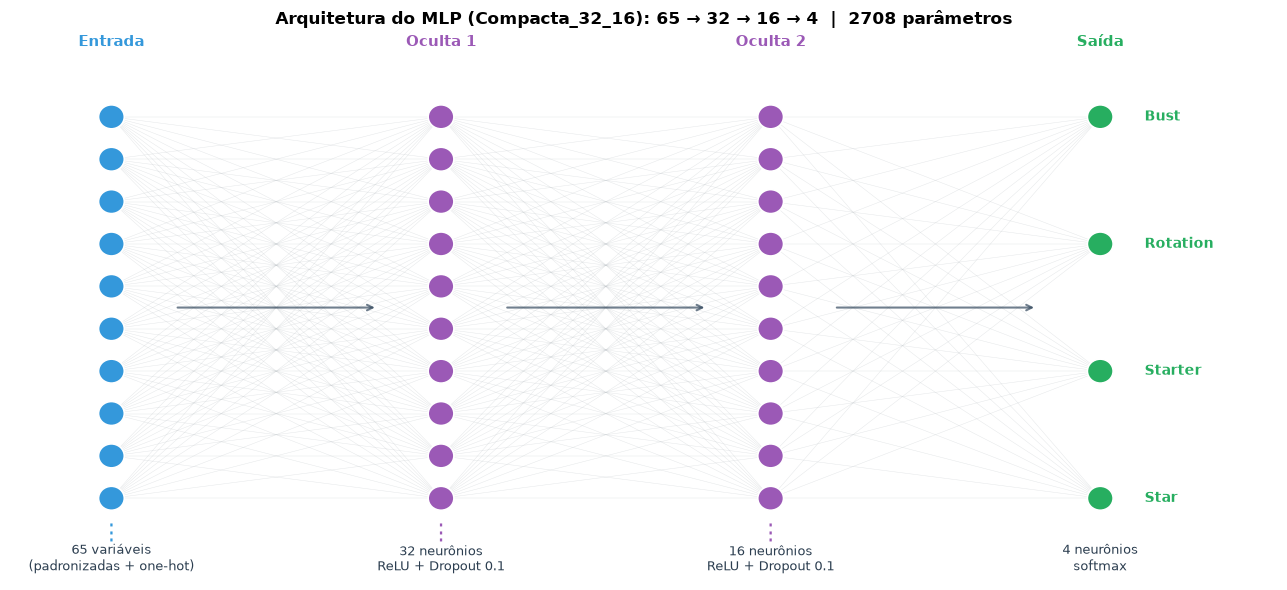

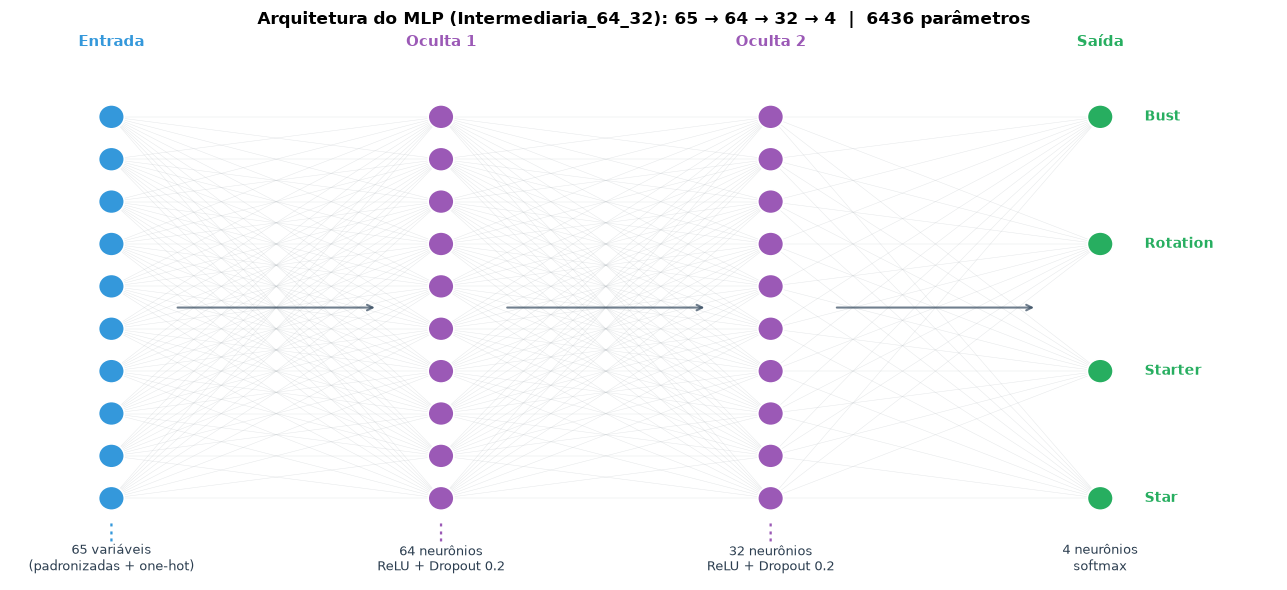

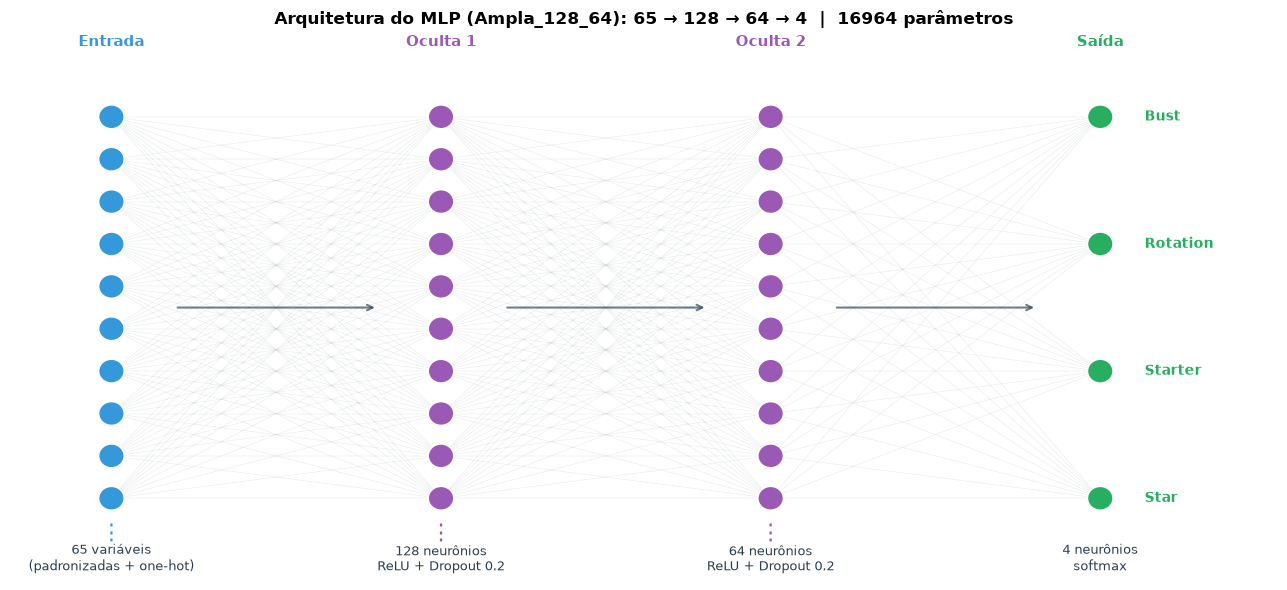

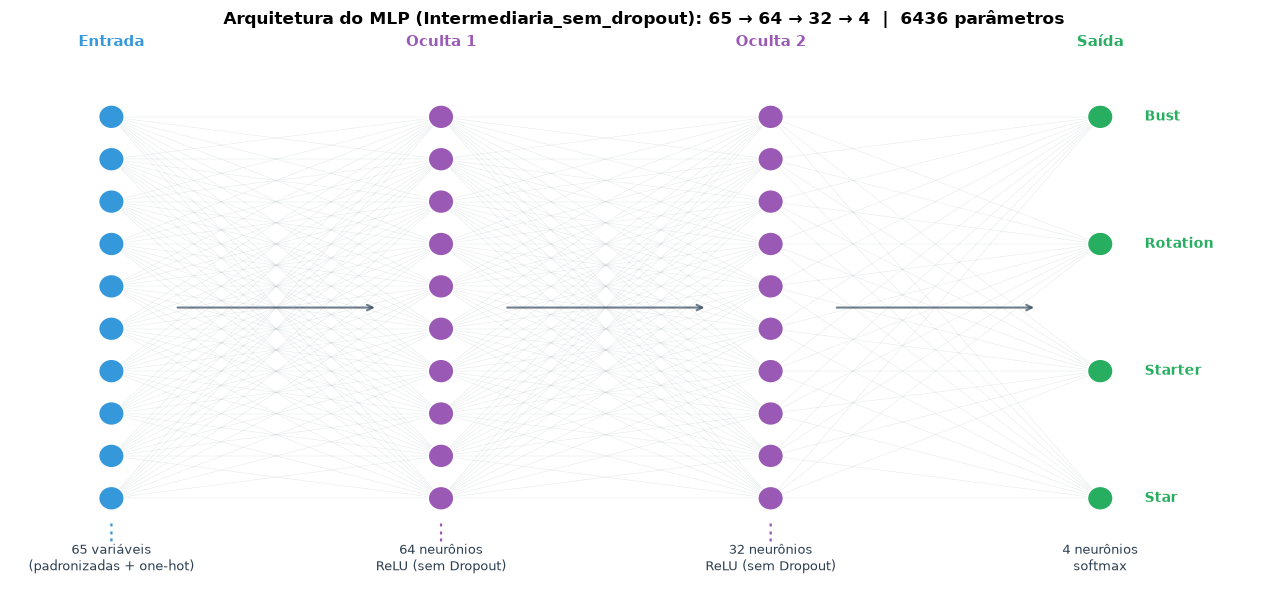

In [28]:
for nome in CONFIGS:
    desenhar_arquitetura(nome)

*Funções para construção e avaliação das redes neurais*

In [30]:
def criar_modelo(config):
    net = keras.Sequential([keras.layers.Input(shape=(X_treino_tratada.shape[1],))])
    for width, drop in zip(config['widths'], config['drops']):
        net.add(keras.layers.Dense(width, activation='relu'))
        net.add(keras.layers.Dropout(drop))
    net.add(keras.layers.Dense(len(ordem_categorias), activation='softmax'))
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=config['lr']),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return net

def metricas(yreal, prob):
    pred = prob.argmax(axis=1)
    return dict(acuracia=accuracy_score(yreal, pred),
        balanced_accuracy=balanced_accuracy_score(yreal, pred),
        f1_macro=f1_score(yreal, pred, labels=classes, average='macro', zero_division=0),
        auc_macro_ovr=roc_auc_score(yreal, prob, labels=classes, multi_class='ovr', average='macro'),
        auc_ovr_ponderada=roc_auc_score(yreal, prob, labels=classes, multi_class='ovr', average='weighted'),  # mesma AUC-OVR do notebook de ML
        log_loss=log_loss(yreal, prob, labels=classes),
        mae_ordinal=mean_absolute_error(yreal, pred),
        kappa_quadratico=cohen_kappa_score(yreal, pred, labels=classes, weights='quadratic'))

class PerdaComparavel(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.treino, self.validacao = [], []
    def on_epoch_end(self, epoch, logs=None):
        pt = self.model(X_treino_tratada, training=False).numpy()
        pv = self.model(X_val_tratada, training=False).numpy()
        self.treino.append(float(log_loss(y_treino, pt, labels=classes)))
        self.validacao.append(float(log_loss(y_val, pv, labels=classes)))

*Tabela de arquiteturas: camadas, parâmetros e parâmetros por amostra de treino.*

In [31]:
n_treino = len(y_treino); n_entrada = X_treino_tratada.shape[1]
tab = []
for nome, cfg in CONFIGS.items():
    keras.backend.clear_session()
    m = criar_modelo(cfg)
    tab.append(dict(modelo=nome,
        arquitetura=f"{n_entrada} → " + " → ".join(str(w) for w in cfg['widths']) + f" → {len(ordem_categorias)}",
        dropout=cfg['drops'], lr_inicial=cfg['lr'], batch=cfg['batch'],
        parametros=m.count_params(), parametros_por_amostra_treino=round(m.count_params() / n_treino, 1)))
tabela_arquiteturas = pd.DataFrame(tab)
display(tabela_arquiteturas)
keras.backend.clear_session()

,modelo,arquitetura,dropout,lr_inicial,batch,parametros,parametros_por_amostra_treino
0,Compacta_32_16,65 → 32 → 16 → 4,"(0.1, 0.1)",0.001,16,2708,4.2
1,Intermediaria_64_32,65 → 64 → 32 → 4,"(0.2, 0.2)",0.001,16,6436,9.9
2,Ampla_128_64,65 → 128 → 64 → 4,"(0.2, 0.2)",0.001,32,16964,26.2
3,Intermediaria_sem_dropout,65 → 64 → 32 → 4,"(0.0, 0.0)",0.001,32,6436,9.9


### **Etapa 5: Construção dos modelos: treinamento com validação, parada antecipada e múltiplas sementes**

In [32]:
linhas, historicos, modelos_fixos, modelos_todos = [], {}, {}, {}
for nome, config in CONFIGS.items():
    for seed in SEEDS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        modelo = criar_modelo(config)
        perdas = PerdaComparavel()
        inicio = time.perf_counter()
        hist = modelo.fit(X_treino_tratada, y_treino, validation_data=(X_val_tratada, y_val), epochs=150,
            batch_size=config['batch'], class_weight=class_weight,
            callbacks=[perdas, keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=.5, patience=7, min_lr=1e-5),
                keras.callbacks.EarlyStopping(
                monitor='val_loss', patience=20, restore_best_weights=True)], verbose=0)
        epoca = int(np.argmin(hist.history['val_loss']) + 1)
        resultado = metricas(y_val, modelo(X_val_tratada, training=False).numpy())
        linhas.append(dict(modelo=nome, seed=seed, parametros=modelo.count_params(),
            epocas=len(hist.history['loss']), melhor_epoca=epoca,
            tempo_segundos=time.perf_counter()-inicio, **resultado))
        historicos[(nome, seed)] = dict(**hist.history,
            ce_treino_comparavel=perdas.treino, ce_val_comparavel=perdas.validacao)
        modelos_todos[(nome, seed)] = modelo
        if seed == SEMENTE_TESTE:
            modelos_fixos[nome] = modelo
        print(nome, seed, 'melhor época:', epoca, 'AUC-OVR validação:', round(resultado['auc_ovr_ponderada'], 3), 'F1 validação:', round(resultado['f1_macro'], 3))
validacao = pd.DataFrame(linhas)

escolhido = validacao.groupby('modelo').auc_ovr_ponderada.mean().idxmax()

Compacta_32_16 123 melhor época: 11 AUC-OVR validação: 0.694 F1 validação: 0.335
Compacta_32_16 7 melhor época: 26 AUC-OVR validação: 0.712 F1 validação: 0.385
Compacta_32_16 42 melhor época: 23 AUC-OVR validação: 0.707 F1 validação: 0.393
Compacta_32_16 2024 melhor época: 37 AUC-OVR validação: 0.75 F1 validação: 0.442
Compacta_32_16 99 melhor época: 23 AUC-OVR validação: 0.728 F1 validação: 0.441
Intermediaria_64_32 123 melhor época: 13 AUC-OVR validação: 0.769 F1 validação: 0.47
Intermediaria_64_32 7 melhor época: 27 AUC-OVR validação: 0.718 F1 validação: 0.394
Intermediaria_64_32 42 melhor época: 15 AUC-OVR validação: 0.715 F1 validação: 0.334
Intermediaria_64_32 2024 melhor época: 25 AUC-OVR validação: 0.754 F1 validação: 0.462
Intermediaria_64_32 99 melhor época: 16 AUC-OVR validação: 0.718 F1 validação: 0.411
Ampla_128_64 123 melhor época: 12 AUC-OVR validação: 0.746 F1 validação: 0.417
Ampla_128_64 7 melhor época: 8 AUC-OVR validação: 0.704 F1 validação: 0.37
Ampla_128_64 42 mel

### **Etapa 6: Comparação de modelos**

*Desempenho na validação por arquitetura (média e desvio entre sementes)*

In [33]:
resumo_val = validacao.groupby('modelo').agg(
    auc_ovr_pond_media=('auc_ovr_ponderada', 'mean'), auc_ovr_pond_dp=('auc_ovr_ponderada', 'std'),
    f1_macro_media=('f1_macro', 'mean'), f1_macro_dp=('f1_macro', 'std'),
    bal_acc_media=('balanced_accuracy', 'mean'), auc_media=('auc_macro_ovr', 'mean'),
    log_loss_media=('log_loss', 'mean'), kappa_quad_media=('kappa_quadratico', 'mean'),
    melhor_epoca_media=('melhor_epoca', 'mean'), melhor_epoca_dp=('melhor_epoca', 'std'),
    parametros=('parametros', 'first')).sort_values('auc_ovr_pond_media', ascending=False)
display(resumo_val.round(3))
print('Modelo selecionado (maior AUC-OVR média na validação):', escolhido)

,auc_ovr_pond_media,auc_ovr_pond_dp,f1_macro_media,f1_macro_dp,bal_acc_media,auc_media,log_loss_media,kappa_quad_media,melhor_epoca_media,melhor_epoca_dp,parametros
modelo,,,,,,,,,,,
Intermediaria_64_32,0.735,0.025,0.414,0.055,0.432,0.724,1.060,0.577,19.2,6.340,6436
Ampla_128_64,0.730,0.020,0.393,0.023,0.428,0.719,1.065,0.550,10.8,2.168,16964
Compacta_32_16,0.718,0.021,0.399,0.045,0.422,0.713,1.079,0.544,24.0,9.274,2708
Intermediaria_sem_dropout,0.717,0.021,0.370,0.011,0.401,0.709,1.088,0.501,14.0,2.828,6436


Modelo selecionado (maior AUC-OVR média na validação): Intermediaria_64_32


*Curvas de perda em treino e validação, por arquitetura e semente*

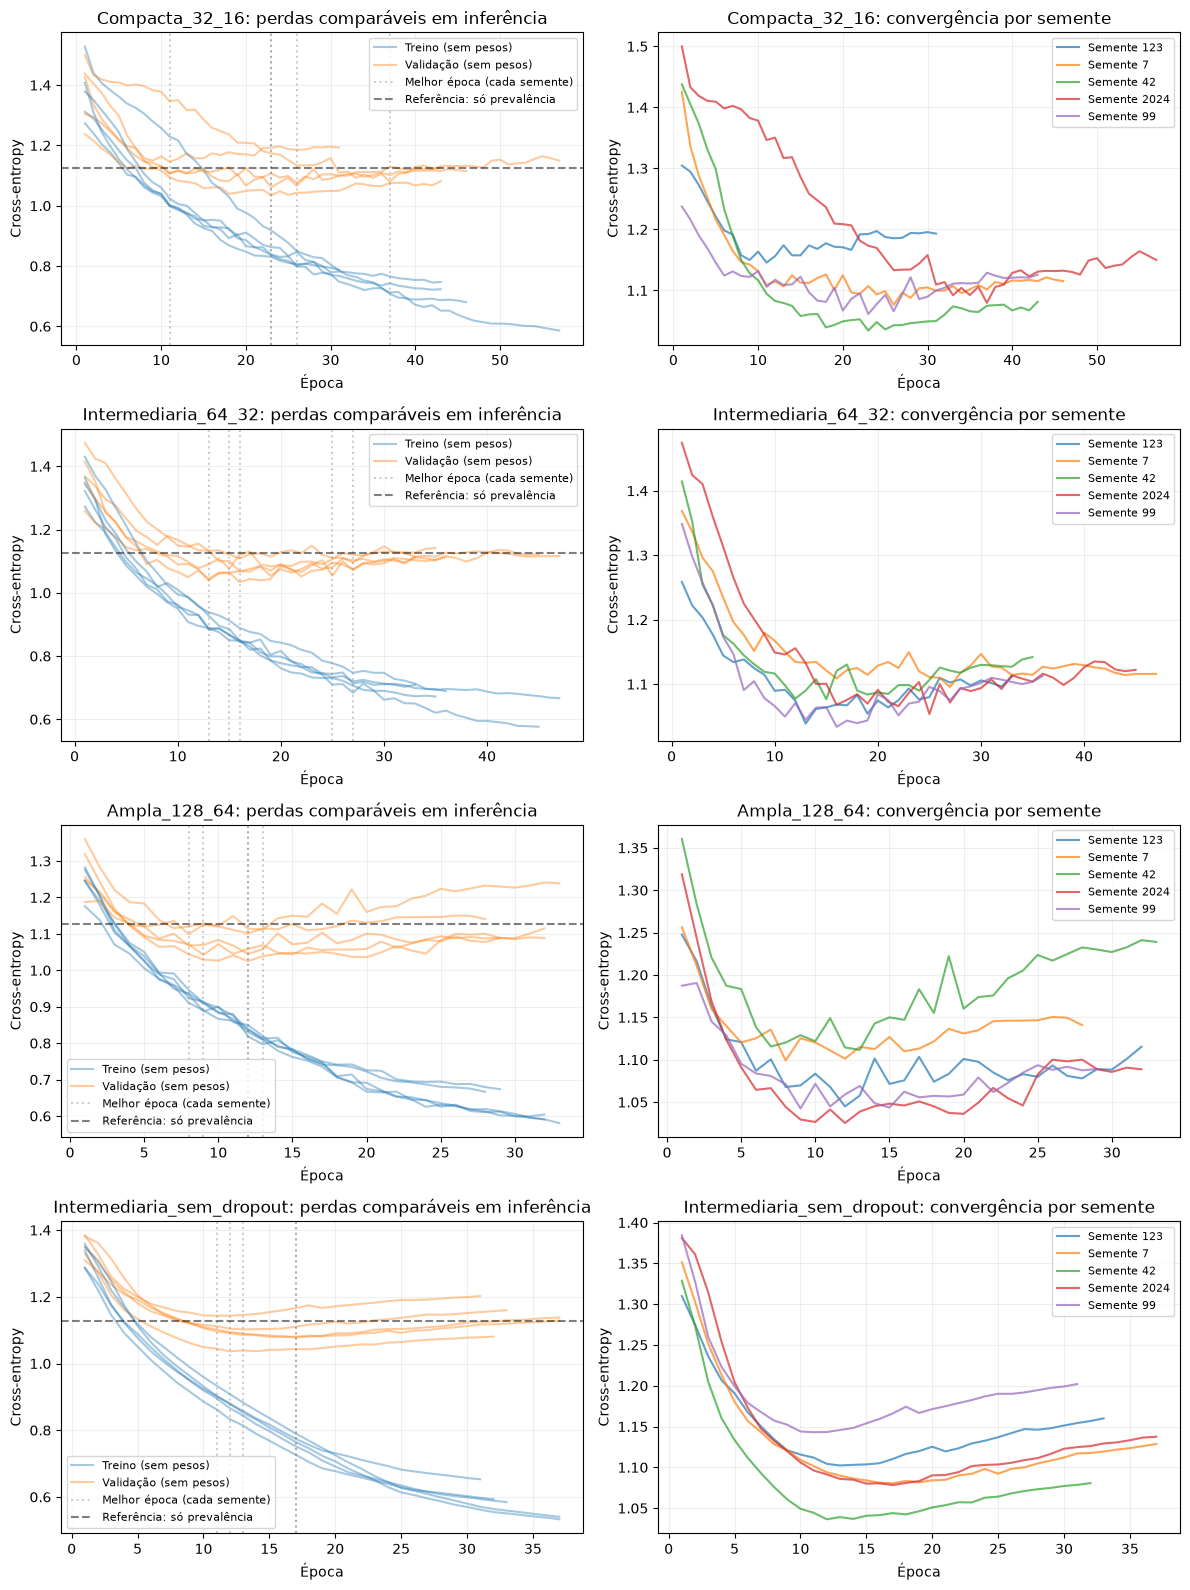

In [34]:
fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(12, 4 * len(CONFIGS)), squeeze=False)
for row, nome in enumerate(CONFIGS):
    for seed in SEEDS:
        h = historicos[(nome, seed)]
        ep = np.arange(1, len(h['loss']) + 1)
        primeiro = seed == SEEDS[0]
        axes[row,0].plot(ep, h['ce_treino_comparavel'], color='tab:blue', alpha=.4,
            label='Treino (sem pesos)' if primeiro else None)
        axes[row,0].plot(ep, h['ce_val_comparavel'], color='tab:orange', alpha=.4,
            label='Validação (sem pesos)' if primeiro else None)
        axes[row,0].axvline(int(np.argmin(h['val_loss'])) + 1, color='gray', linestyle=':', alpha=.4,
            label='Melhor época (cada semente)' if primeiro else None)
        axes[row,1].plot(ep, h['val_loss'], alpha=.7, label=f'Semente {seed}')
    axes[row,0].axhline(ce_prior_val, color='k', linestyle='--', alpha=.5, label='Referência: só prevalência')
    axes[row,0].set_title(f'{nome}: perdas comparáveis em inferência')
    axes[row,1].set_title(f'{nome}: convergência por semente')
    for ax in axes[row]:
        ax.set(xlabel='Época', ylabel='Cross-entropy'); ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

*Diagnóstico de overfitting, underfitting e convergência*

In [35]:
diagnosticos = []
for (nome, seed), h in historicos.items():
    melhor = int(np.argmin(h['val_loss']))
    ce_t, ce_v = np.asarray(h['ce_treino_comparavel']), np.asarray(h['ce_val_comparavel'])
    lr = h.get('learning_rate', h.get('lr'))
    diagnosticos.append({'modelo': nome, 'seed': seed, 'melhor_epoca': melhor + 1, 'epocas': len(ce_v),
        'atingiu_teto': len(ce_v) == 150,
        'ce_treino_melhor': ce_t[melhor], 'ce_val_melhor': ce_v[melhor],
        'gap_val_menos_treino': ce_v[melhor] - ce_t[melhor],
        'piora_val_apos_melhor': ce_v[-1] - ce_v[melhor],
        'queda_treino_apos_melhor': ce_t[melhor] - ce_t[-1],
        'reducoes_lr': int(round(np.log2(lr[0] / lr[-1]))) if lr is not None else np.nan})
diagnosticos = pd.DataFrame(diagnosticos)
display(diagnosticos.round(3))

,modelo,seed,melhor_epoca,epocas,atingiu_teto,ce_treino_melhor,ce_val_melhor,gap_val_menos_treino,piora_val_apos_melhor,queda_treino_apos_melhor,reducoes_lr
0,Compacta_32_16,123,11,31,False,1.002,1.146,0.144,0.047,0.215,2
1,Compacta_32_16,7,26,46,False,0.800,1.076,0.277,0.039,0.119,2
2,Compacta_32_16,42,23,43,False,0.863,1.034,0.171,0.047,0.115,2
3,Compacta_32_16,2024,37,57,False,0.708,1.080,0.372,0.070,0.122,2
4,Compacta_32_16,99,23,43,False,0.838,1.061,0.223,0.065,0.115,2
5,Intermediaria_64_32,123,13,33,False,0.889,1.039,0.150,0.073,0.179,2
6,Intermediaria_64_32,7,27,47,False,0.747,1.096,0.348,0.021,0.080,3
7,Intermediaria_64_32,42,15,35,False,0.850,1.077,0.227,0.065,0.178,2
8,Intermediaria_64_32,2024,25,45,False,0.710,1.054,0.344,0.069,0.133,2
9,Intermediaria_64_32,99,16,36,False,0.845,1.034,0.189,0.079,0.156,2


*Estabilidade entre sementes*

,melhor_epoca_media,melhor_epoca_dp,ce_val_melhor_media,ce_val_melhor_dp,gap_medio,piora_pos_melhor_media,atingiu_teto,auc_media,auc_dp,f1_media,f1_dp,auc_coef_variacao,f1_coef_variacao
modelo,,,,,,,,,,,,,
Ampla_128_64,10.8,2.168,1.065,0.038,0.209,0.070,0,0.730,0.020,0.393,0.023,0.027,0.059
Compacta_32_16,24.0,9.274,1.079,0.041,0.237,0.054,0,0.718,0.021,0.399,0.045,0.030,0.112
Intermediaria_64_32,19.2,6.340,1.060,0.026,0.252,0.061,0,0.735,0.025,0.414,0.055,0.034,0.134
Intermediaria_sem_dropout,14.0,2.828,1.088,0.039,0.261,0.054,0,0.717,0.021,0.370,0.011,0.030,0.031


Referência (prever só a prevalência): cross-entropy de validação = 1.126


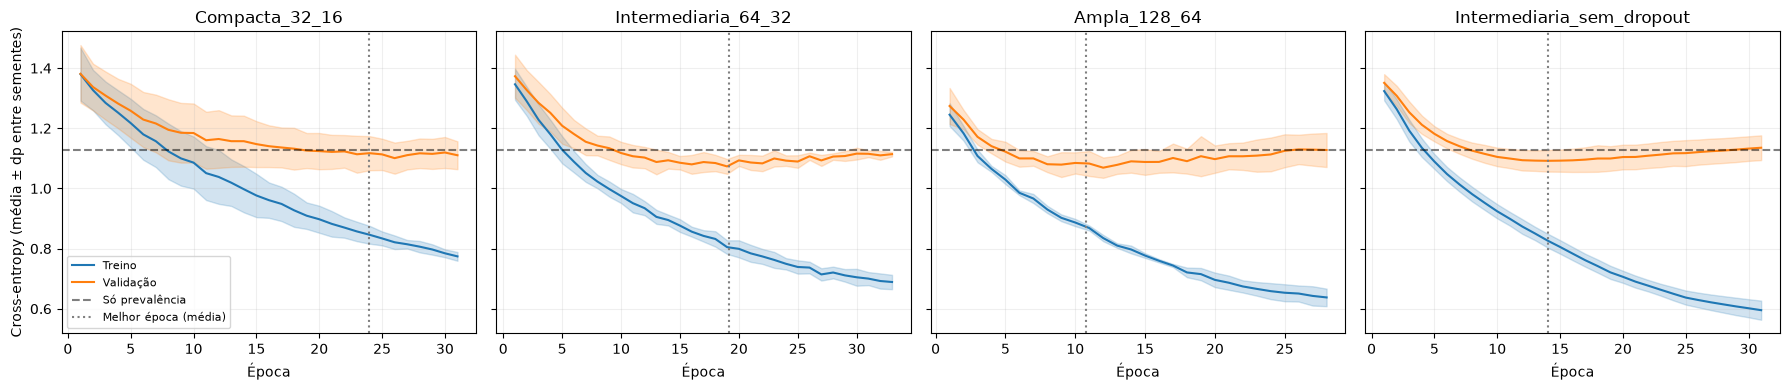

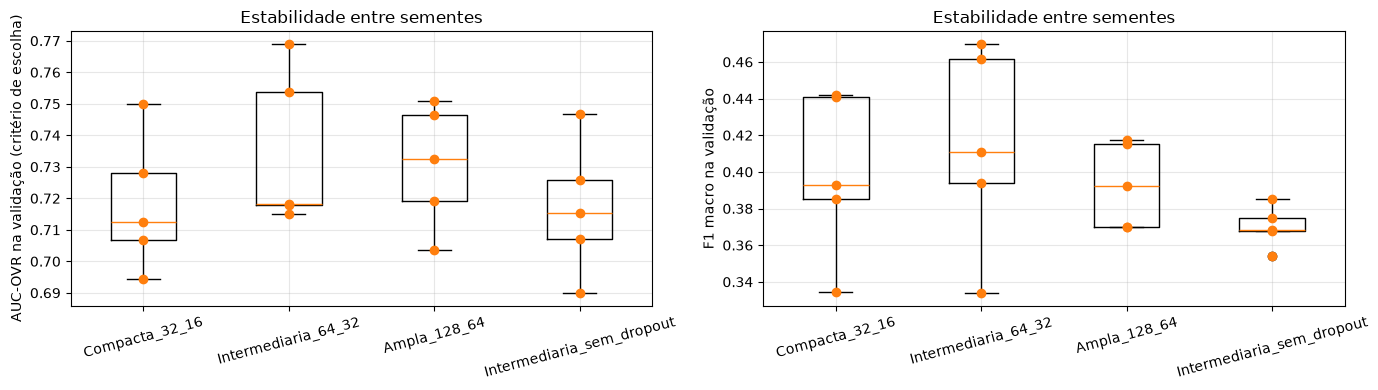

[Text(0.5, 0, 'AUC-OVR na validação (média e desvio entre sementes)'),
 Text(0, 0.5, 'Configuração'),
 (0.5, 1.0)]

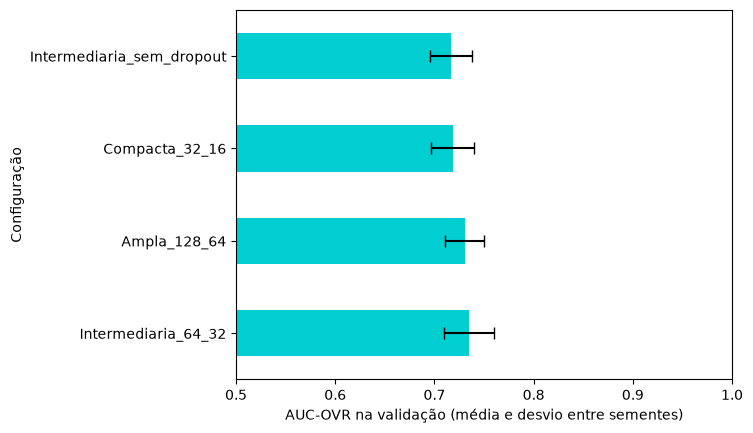

In [36]:
estabilidade = diagnosticos.groupby('modelo').agg(
    melhor_epoca_media=('melhor_epoca', 'mean'), melhor_epoca_dp=('melhor_epoca', 'std'),
    ce_val_melhor_media=('ce_val_melhor', 'mean'), ce_val_melhor_dp=('ce_val_melhor', 'std'),
    gap_medio=('gap_val_menos_treino', 'mean'), piora_pos_melhor_media=('piora_val_apos_melhor', 'mean'),
    atingiu_teto=('atingiu_teto', 'sum')).join(
    validacao.groupby('modelo').agg(auc_media=('auc_ovr_ponderada', 'mean'), auc_dp=('auc_ovr_ponderada', 'std'),
                                    f1_media=('f1_macro', 'mean'), f1_dp=('f1_macro', 'std')))
estabilidade['auc_coef_variacao'] = estabilidade.auc_dp / estabilidade.auc_media
estabilidade['f1_coef_variacao'] = estabilidade.f1_dp / estabilidade.f1_media
display(estabilidade.round(3))
print('Referência (prever só a prevalência): cross-entropy de validação =', round(ce_prior_val, 3))

fig, axes = plt.subplots(1, len(CONFIGS), figsize=(4.5 * len(CONFIGS), 4), sharey=True)
for ax, nome in zip(axes, CONFIGS):
    hs = [historicos[(nome, s)] for s in SEEDS]
    n = min(len(h['loss']) for h in hs)           # curvas truncadas no menor número de épocas entre sementes
    ep = np.arange(1, n + 1)
    for chave, cor, rot in [('ce_treino_comparavel', 'tab:blue', 'Treino'), ('ce_val_comparavel', 'tab:orange', 'Validação')]:
        M = np.array([h[chave][:n] for h in hs])
        ax.plot(ep, M.mean(0), color=cor, label=rot)
        ax.fill_between(ep, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color=cor, alpha=.2)
    ax.axhline(ce_prior_val, color='k', linestyle='--', alpha=.5, label='Só prevalência')
    ax.axvline(estabilidade.loc[nome, 'melhor_epoca_media'], color='gray', linestyle=':', label='Melhor época (média)')
    ax.set(title=nome, xlabel='Época'); ax.grid(alpha=.2)
axes[0].set_ylabel('Cross-entropy (média ± dp entre sementes)'); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

# Estabilidade entre sementes: AUC-OVR (critério de escolha) e F1 macro (apoio)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, coluna, rotulo in [(axes[0], 'auc_ovr_ponderada', 'AUC-OVR na validação (critério de escolha)'),
                           (axes[1], 'f1_macro', 'F1 macro na validação')]:
    dados_box = [validacao.loc[validacao.modelo == n, coluna].values for n in CONFIGS]
    ax.boxplot(dados_box); ax.set_xticklabels(list(CONFIGS), rotation=15)
    for i, v in enumerate(dados_box, start=1):
        ax.scatter(np.full(len(v), i), v, color='tab:orange', zorder=3)
    ax.set(ylabel=rotulo, title='Estabilidade entre sementes'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

ranking = validacao.groupby('modelo').auc_ovr_ponderada.agg(['mean', 'std']).sort_values('mean', ascending=False)
erros = ranking['std'] if len(SEEDS) > 1 else None
ax = ranking['mean'].plot.barh(xerr=erros, color='darkturquoise', capsize=4)
rotulo_auc = 'AUC-OVR na validação'
if erros is not None:
    rotulo_auc += ' (média e desvio entre sementes)'
ax.set(xlabel=rotulo_auc, ylabel='Configuração', xlim=(0.5, 1))   # 0,5 = acaso

### **Etapa 7: Escolha do modelo**

*Escolha do modelo*

In [37]:
nome_modelo_escolhido = escolhido   # maior AUC-OVR média na validação (Etapa 5)

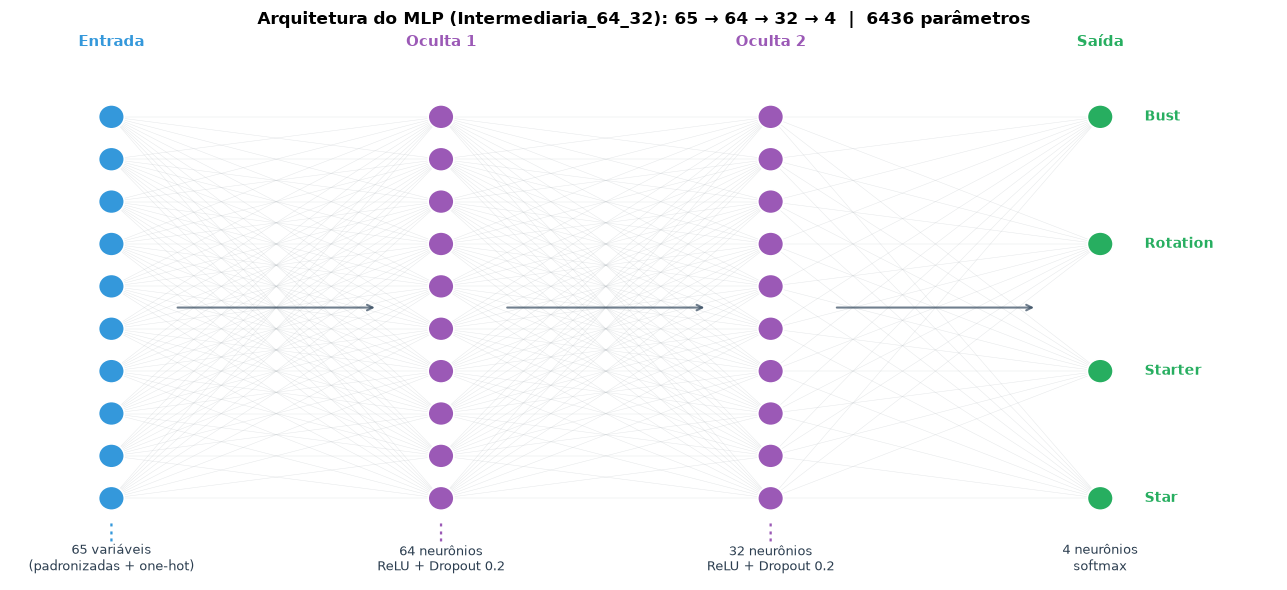

In [38]:
desenhar_arquitetura(nome_modelo_escolhido)

*Características do modelo escolhido*

In [39]:
cfg = CONFIGS[nome_modelo_escolhido]
linha = resumo_val.loc[nome_modelo_escolhido]
print(f"O modelo final adotado foi uma rede neural MLP ({nome_modelo_escolhido}), com camadas ocultas {cfg['widths']}, dropout {cfg['drops']}, "
      f"taxa de aprendizado inicial {cfg['lr']}, batch {cfg['batch']} e {int(linha['parametros'])} parâmetros.")
print(f"Validação: AUC-OVR média = {linha['auc_ovr_pond_media']:.3f} (dp = {linha['auc_ovr_pond_dp']:.3f}) e F1 macro médio = {linha['f1_macro_media']:.3f} entre {len(SEEDS)} sementes; "
      f"melhor época média = {linha['melhor_epoca_media']:.1f}.")

O modelo final adotado foi uma rede neural MLP (Intermediaria_64_32), com camadas ocultas (64, 32), dropout (0.2, 0.2), taxa de aprendizado inicial 0.001, batch 16 e 6436 parâmetros.
Validação: AUC-OVR média = 0.735 (dp = 0.025) e F1 macro médio = 0.414 entre 5 sementes; melhor época média = 19.2.


*Modelo final (pesos da melhor época da semente de referência) e linha de base: previsão apenas pela prevalência do treino*

In [40]:
modelo_final = modelos_fixos[nome_modelo_escolhido]
baseline = DummyClassifier(strategy='prior').fit(X_treino_tratada, y_treino)

*Plota as curvas de aprendizado: perda, acurácia e sinal de overfitting.*

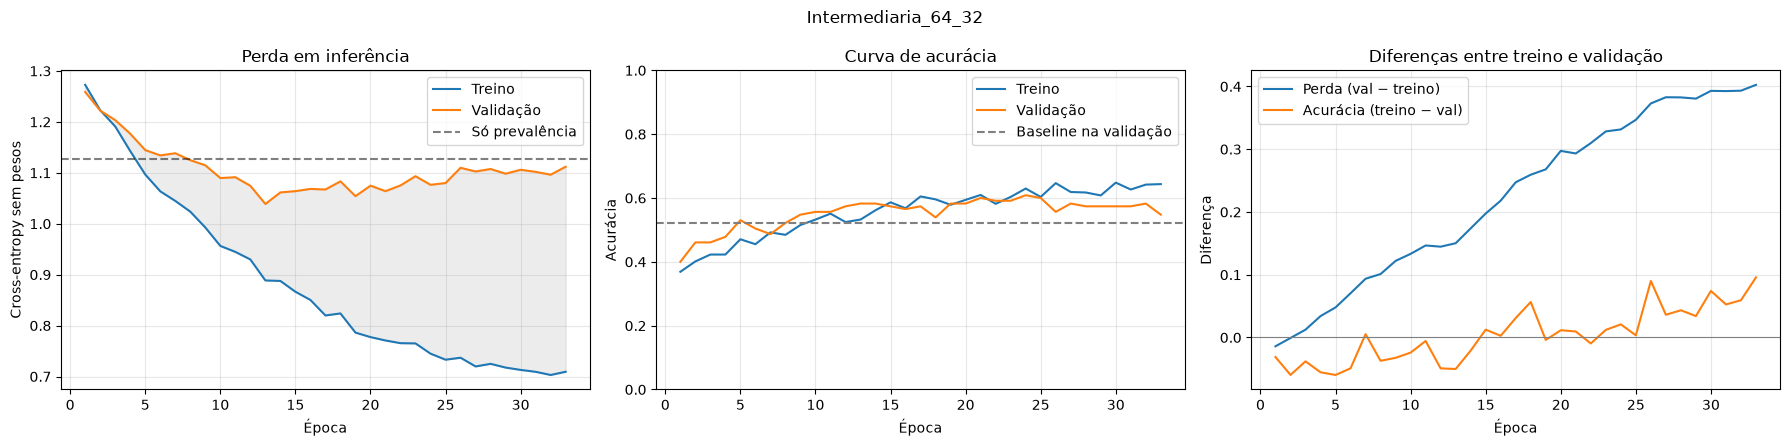

In [41]:
historico_escolhido = historicos[(escolhido, SEMENTE_TESTE)]
epocas = np.arange(1, len(historico_escolhido['loss']) + 1)
ce_treino = np.asarray(historico_escolhido['ce_treino_comparavel'])
ce_val = np.asarray(historico_escolhido['ce_val_comparavel'])
acc_treino = np.asarray(historico_escolhido['accuracy'])
acc_val = np.asarray(historico_escolhido['val_accuracy'])
acc_baseline_val = accuracy_score(y_val, baseline.predict(X_val_tratada))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(epocas, ce_treino, label='Treino')
axes[0].plot(epocas, ce_val, label='Validação')
axes[0].fill_between(epocas, ce_treino, ce_val, color='gray', alpha=.15)
axes[0].axhline(ce_prior_val, color='k', linestyle='--', alpha=.5, label='Só prevalência')
axes[0].set(title='Perda em inferência', ylabel='Cross-entropy sem pesos')

axes[1].plot(epocas, acc_treino, label='Treino')
axes[1].plot(epocas, acc_val, label='Validação')
axes[1].axhline(acc_baseline_val, color='gray', linestyle='--', label='Baseline na validação')
axes[1].set(title='Curva de acurácia', ylabel='Acurácia', ylim=(0, 1))

axes[2].plot(epocas, ce_val - ce_treino, label='Perda (val − treino)')
axes[2].plot(epocas, acc_treino - acc_val, label='Acurácia (treino − val)')
axes[2].axhline(0, color='gray', linewidth=.8)
axes[2].set(title='Diferenças entre treino e validação', ylabel='Diferença')

for ax in axes:
    ax.set_xlabel('Época')
    ax.legend()
    ax.grid(alpha=.3)
fig.suptitle(escolhido)
fig.tight_layout()
plt.show()

### **Etapa 8: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [42]:
Xte = X_teste_tratada
yte = np.asarray(y_teste, dtype='int32')
p_hat_teste = modelo_final(Xte, training=False).numpy()
classes = np.unique(y_treino)

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [43]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

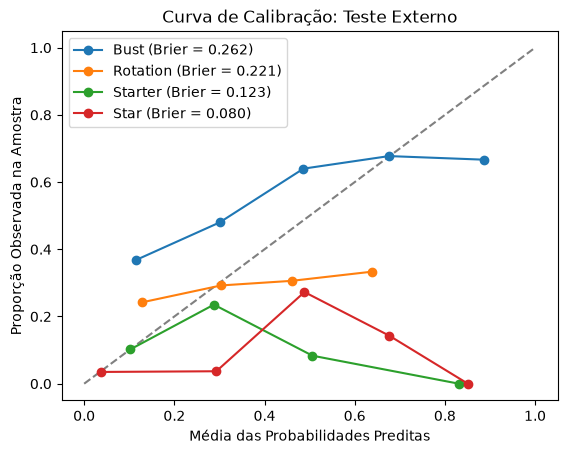

In [44]:
# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Correção das probabilidades preditas no teste pelo efeito dos pesos de classe do treino*

In [45]:
# Com class_weight='balanced' a rede aprende como se as classes fossem equiprováveis; razão entre a prevalência real e a efetiva no treino
prev_real = np.bincount(y_treino, minlength=len(classes)) / len(y_treino)
prev_efetiva = prev_real * weights
prev_efetiva = prev_efetiva / prev_efetiva.sum()
w = prev_real / prev_efetiva

# Armazenamento de probabilidades originais e cálculo das probabilidades corrigidas
p_hat_teste_nao_corrigidas = p_hat_teste
p_hat_teste_corrigidas = p_hat_teste * w
p_hat_teste_corrigidas = p_hat_teste_corrigidas / p_hat_teste_corrigidas.sum(axis=1, keepdims=True)

def brier_medio(P):
    return np.mean([brier_score_loss((y_teste == cls).astype(int), P[:, k]) for k, cls in enumerate(classes)])

pd.DataFrame({'log_loss': [log_loss(y_teste, P, labels=classes) for P in (p_hat_teste_nao_corrigidas, p_hat_teste_corrigidas)],
              'brier_medio': [brier_medio(P) for P in (p_hat_teste_nao_corrigidas, p_hat_teste_corrigidas)]},
             index=['Probabilidades originais', 'Probabilidades corrigidas']).round(3)

,log_loss,brier_medio
Probabilidades originais,1.216,0.172
Probabilidades corrigidas,1.114,0.155


*Verificação gráfica de calibração das probabilidades*

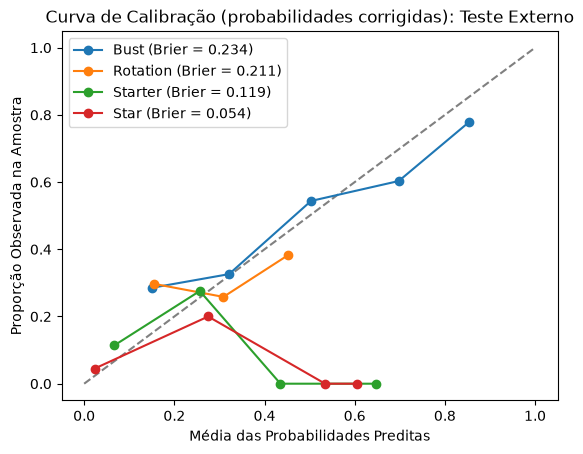

In [46]:
# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste_corrigidas[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste_corrigidas[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração (probabilidades corrigidas): Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [47]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste).reindex(index=classes, columns=classes, fill_value=0)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,Bust,Rotation,Starter,Star
Bust,50,31,7,12
Rotation,21,16,11,7
Starter,5,9,5,7
Star,2,2,2,4


In [48]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3).fillna(0)
tabela_relativa_linhas

,Bust,Rotation,Starter,Star
Bust,0.500,0.310,0.070,0.120
Rotation,0.382,0.291,0.200,0.127
Starter,0.192,0.346,0.192,0.269
Star,0.200,0.200,0.200,0.400


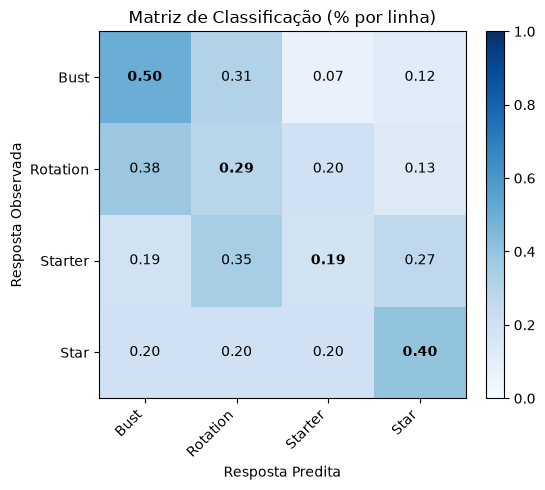

In [49]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [50]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3).fillna(0)
tabela_relativa_colunas

,Bust,Rotation,Starter,Star
Bust,0.641,0.534,0.28,0.400
Rotation,0.269,0.276,0.44,0.233
Starter,0.064,0.155,0.20,0.233
Star,0.026,0.034,0.08,0.133


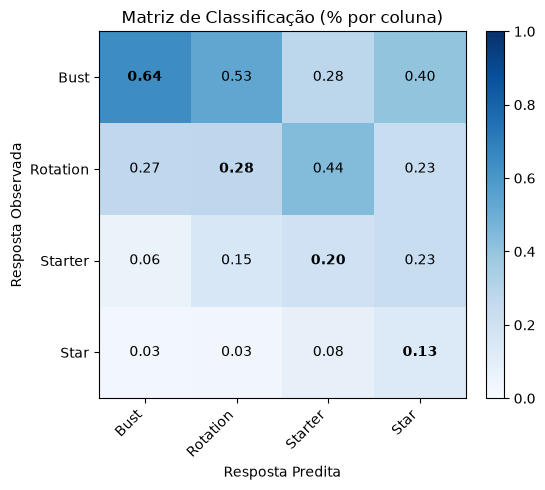

In [51]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_colunas.values):
    same_label = tabela_relativa_colunas.index[i] == tabela_relativa_colunas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [52]:
# Taxas de acerto por categoria (recalls)
pd.Series(np.diag(tabela_relativa_linhas.to_numpy()), index=tabela_relativa_linhas.index)

Bust        0.500
Rotation    0.291
Starter     0.192
Star        0.400
dtype: float64

In [53]:
# Precisões por categoria
pd.Series(np.diag(tabela_relativa_colunas.to_numpy()), index=tabela_relativa_colunas.index)

Bust        0.641
Rotation    0.276
Starter     0.200
Star        0.133
dtype: float64

In [54]:
# AUC-OVR, acurácia e acurácia balanceada (mesmas métricas do notebook de ML) + métricas adicionais do problema ordinal
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='weighted')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)
f1_macro_teste = f1_score(y_teste, y_hat_teste, labels=classes, average='macro', zero_division=0)
kappa_quadratico_teste = cohen_kappa_score(y_teste, y_hat_teste, labels=classes, weights='quadratic')
mae_ordinal_teste = mean_absolute_error(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')
print(f'F1 macro: {f1_macro_teste:.3f}')
print(f'Kappa quadrático: {kappa_quadratico_teste:.3f}')
print(f'MAE ordinal: {mae_ordinal_teste:.3f}')

AUC-OVR: 0.624
Acurácia: 0.393
Acurácia balanceada: 0.346
F1 macro: 0.310
Kappa quadrático: 0.259
MAE ordinal: 0.864


*Curvas ROC e de precisão-revocação por classe (one-versus-rest)*

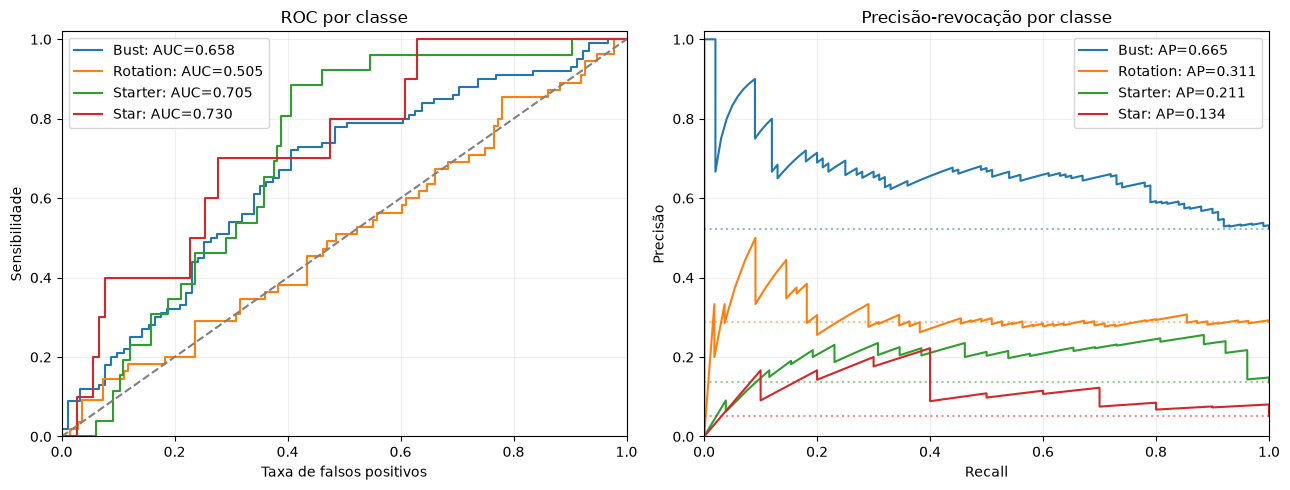

In [55]:
prob_final = modelos_fixos[escolhido](X_teste_tratada, training=False).numpy()
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for classe, nome in enumerate(ordem_categorias):
    binario = (yte == classe).astype(int)
    fpr, tpr, _ = roc_curve(binario, prob_final[:, classe])
    precision, recall, _ = precision_recall_curve(binario, prob_final[:, classe])
    auc_classe = roc_auc_score(binario, prob_final[:, classe])
    ap = average_precision_score(binario, prob_final[:, classe])
    line, = axes[0].plot(fpr, tpr, label=f'{nome}: AUC={auc_classe:.3f}')
    axes[1].plot(recall, precision, color=line.get_color(), label=f'{nome}: AP={ap:.3f}')
    axes[1].axhline(binario.mean(), color=line.get_color(), linestyle=':', alpha=.5)
axes[0].plot([0,1], [0,1], '--', color='gray')
axes[0].set(xlabel='Taxa de falsos positivos', ylabel='Sensibilidade', title='ROC por classe')
axes[1].set(xlabel='Recall', ylabel='Precisão', title='Precisão-revocação por classe')
for ax in axes:
    ax.legend(); ax.grid(alpha=.2); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
plt.tight_layout();
plt.show()


*Comparação com a linha de base e com as demais arquiteturas no teste externo (apenas relato: a escolha foi feita na validação)*

In [56]:
finais = [dict(modelo='Baseline_prior', **metricas(yte, baseline.predict_proba(Xte)))]
for nome, modelo in modelos_fixos.items():
    finais.append(dict(modelo=nome, **metricas(yte, modelo(Xte, training=False).numpy())))
final = pd.DataFrame(finais)
display(final)

,modelo,acuracia,balanced_accuracy,f1_macro,auc_macro_ovr,auc_ovr_ponderada,log_loss,mae_ordinal,kappa_quadratico
0,Baseline_prior,0.523560,0.250000,0.171821,0.500000,0.500000,1.123307,0.717277,0.000000
1,Compacta_32_16,0.356021,0.324213,0.284751,0.575598,0.571197,1.284843,0.942408,0.219366
2,Intermediaria_64_32,0.392670,0.345804,0.310266,0.649587,0.624253,1.216266,0.863874,0.259463
3,Ampla_128_64,0.418848,0.350122,0.315308,0.625003,0.608763,1.268932,0.811518,0.314478
4,Intermediaria_sem_dropout,0.424084,0.379213,0.335295,0.620513,0.600444,1.248756,0.795812,0.326643


In [57]:
# Estabilidade no teste externo: todas as sementes (apenas relato; a escolha já foi feita na validação)
linhas_teste = [dict(modelo=nome, seed=seed, **metricas(yte, m(Xte, training=False).numpy()))
                for (nome, seed), m in modelos_todos.items()]
teste_sementes = pd.DataFrame(linhas_teste)
resumo_teste = teste_sementes.drop(columns='seed').groupby('modelo').agg(['mean', 'std'])
display(resumo_teste.round(3))

# IC 95% por bootstrap do modelo selecionado (semente SEMENTE_TESTE) e comparação com a linha de base
rng = np.random.default_rng(123)
pred_esc = modelos_fixos[escolhido](Xte, training=False).numpy().argmax(axis=1)
pred_base = baseline.predict(Xte)
def _m(y_, p_):
    return (accuracy_score(y_, p_), balanced_accuracy_score(y_, p_),
            f1_score(y_, p_, labels=classes, average='macro', zero_division=0))
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yte), len(yte))
    boot.append(_m(yte[i], pred_esc[i]))
ic = np.percentile(boot, [2.5, 97.5], axis=0)
pontual, base = _m(yte, pred_esc), _m(yte, pred_base)
print(f'IC 95% (bootstrap, n_teste={len(yte)}) do modelo selecionado: {escolhido}')
for k, nome_m in enumerate(['Acurácia', 'Acurácia balanceada', 'F1 macro']):
    print(f'  {nome_m}: {pontual[k]:.3f} [{ic[0][k]:.3f}; {ic[1][k]:.3f}] | baseline = {base[k]:.3f}')

acuracia        balanced_accuracy        f1_macro  \
                              mean    std              mean    std     mean   
modelo                                                                        
Ampla_128_64                 0.412  0.016             0.338  0.017    0.303   
Compacta_32_16               0.406  0.029             0.334  0.027    0.305   
Intermediaria_64_32          0.414  0.025             0.343  0.043    0.314   
Intermediaria_sem_dropout    0.425  0.024             0.383  0.036    0.333   

                                 auc_macro_ovr        auc_ovr_ponderada  \
                             std          mean    std              mean   
modelo                                                                    
Ampla_128_64               0.017         0.627  0.007             0.606   
Compacta_32_16             0.020         0.625  0.035             0.604   
Intermediaria_64_32        0.029         0.634  0.012             0.613   
Intermediaria_sem_dropout  0.028         0.623  0.020             0.600   

                                 log_loss        mae_ordinal         \
                             std     mean    std        mean    std   
modelo                                                                
Ampla_128_64               0.007    1.249  0.015       0.807  0.019   
Compacta_32_16             0.030    1.270  0.054       0.826  0.070   
Intermediaria_64_32        0.009    1.239  0.034       0.808  0.036   
Intermediaria_sem_dropout  0.015    1.256  0.029       0.797  0.012   

                          kappa_quadratico         
                                      mean    std  
modelo                                             
Ampla_128_64                         0.327  0.015  
Compacta_32_16                       0.293  0.059  
Intermediaria_64_32                  0.309  0.036  
Intermediaria_sem_dropout            0.330  0.024

IC 95% (bootstrap, n_teste=191) do modelo selecionado: Intermediaria_64_32
  Acurácia: 0.393 [0.325; 0.466] | baseline = 0.524
  Acurácia balanceada: 0.346 [0.252; 0.450] | baseline = 0.250
  F1 macro: 0.310 [0.241; 0.383] | baseline = 0.172


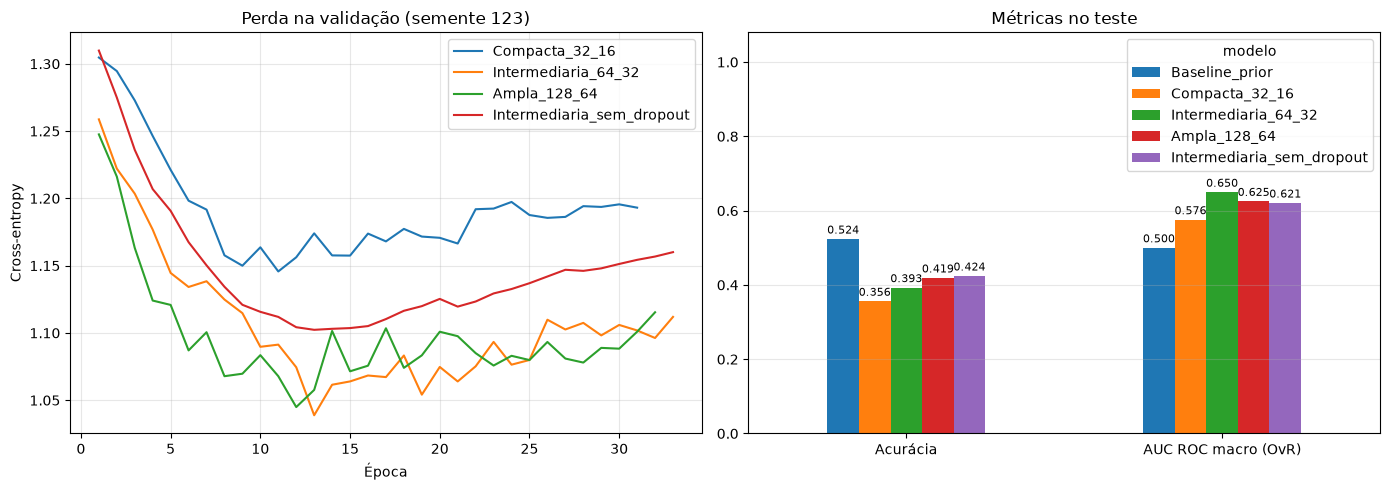

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nome in CONFIGS:
    perdas_val = historicos[(nome, SEMENTE_TESTE)]['val_loss']
    axes[0].plot(np.arange(1, len(perdas_val) + 1), perdas_val, label=nome)
axes[0].set(xlabel='Época', ylabel='Cross-entropy', title=f'Perda na validação (semente {SEMENTE_TESTE})')
axes[0].legend()
axes[0].grid(alpha=.3)

comparacao = final.set_index('modelo')[['acuracia', 'auc_macro_ovr']].T
comparacao.index = ['Acurácia', 'AUC ROC macro (OvR)']
comparacao.plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Métricas no teste', ylim=(0, 1.08))
for barras in axes[1].containers:
    axes[1].bar_label(barras, fmt='%.3f', padding=2, fontsize=8)
axes[1].grid(axis='y', alpha=.3)
fig.tight_layout()
plt.show()

### **Etapa 9: Interpretabilidade do modelo final**

*Cálculo da importância por permutação para cada variável no modelo final (queda na AUC-OVR do conjunto de validação ao embaralhar a variável)*

In [59]:
N_REPETICOES = 30
rng_perm = np.random.default_rng(123)

def auc_ovr_modelo(X_, y_):
    return roc_auc_score(y_, modelo_final(X_, training=False).numpy(), labels=classes, multi_class='ovr', average='weighted')

score_base = auc_ovr_modelo(X_val_tratada, y_val)
queda = np.zeros((len(nomes_variaveis), N_REPETICOES))
for j in range(len(nomes_variaveis)):
    for r in range(N_REPETICOES):
        X_perm = X_val_tratada.copy()
        X_perm[:, j] = rng_perm.permutation(X_perm[:, j])
        queda[j, r] = score_base - auc_ovr_modelo(X_perm, y_val)
importancias_permutacao = pd.Series(queda.mean(axis=1), index=nomes_variaveis).sort_values()

*Gráfico de importâncias por permutação*

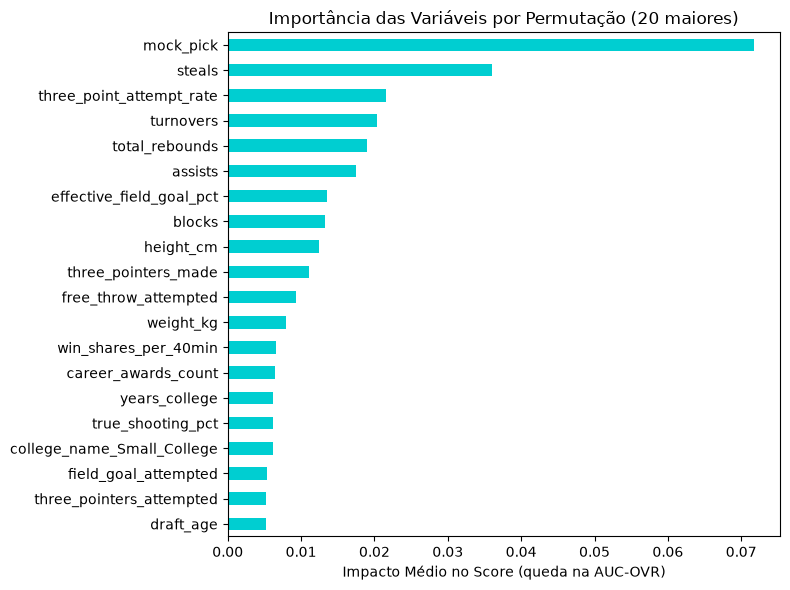

In [60]:
plt.figure(figsize=(8, 6))
importancias_permutacao.tail(20).plot.barh(title="Importância das Variáveis por Permutação (20 maiores)",
                                           color="darkturquoise")
plt.xlabel("Impacto Médio no Score (queda na AUC-OVR)")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [61]:
X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
explainer = shap.Explainer(modelo_final, X_amostra)
valores_shap = explainer(X_amostra)
valores_shap.feature_names = list(nomes_variaveis)


Background dataset has 648 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=648 when initializing the masker.
PermutationExplainer explainer: 649it [00:43, 11.40it/s]                         


*Gráfico de valores absolutos médios de SHAP*

Gerando SHAP Bar Plot para a classe: Bust


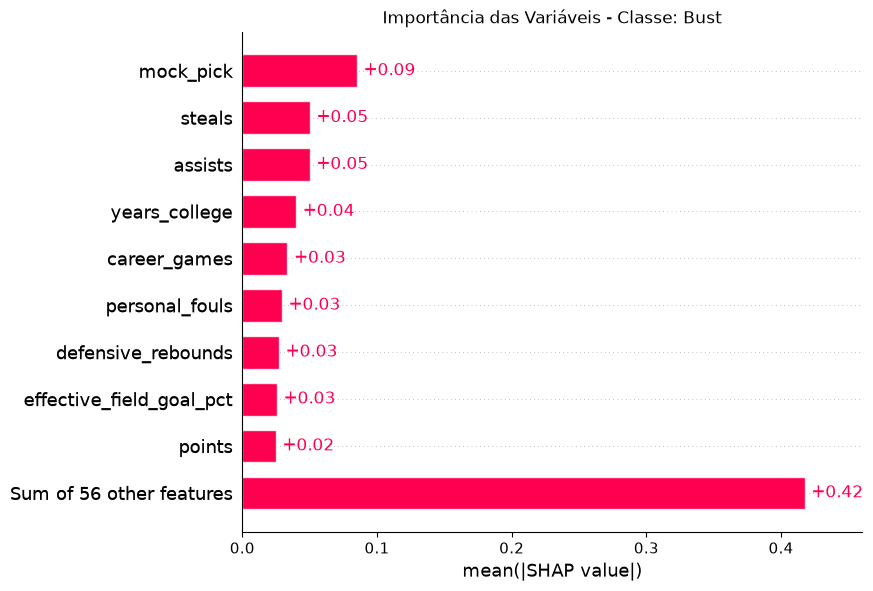

Gerando SHAP Bar Plot para a classe: Rotation


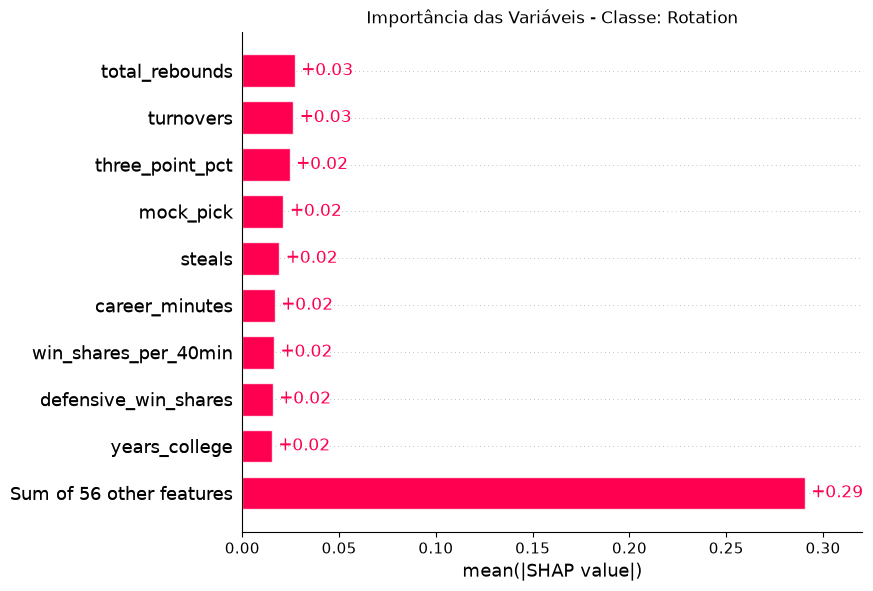

Gerando SHAP Bar Plot para a classe: Starter


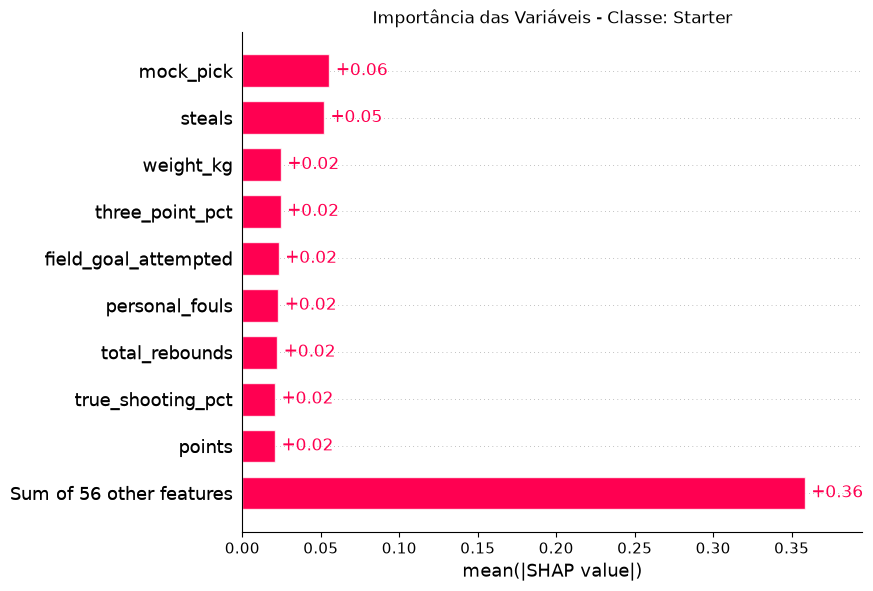

Gerando SHAP Bar Plot para a classe: Star


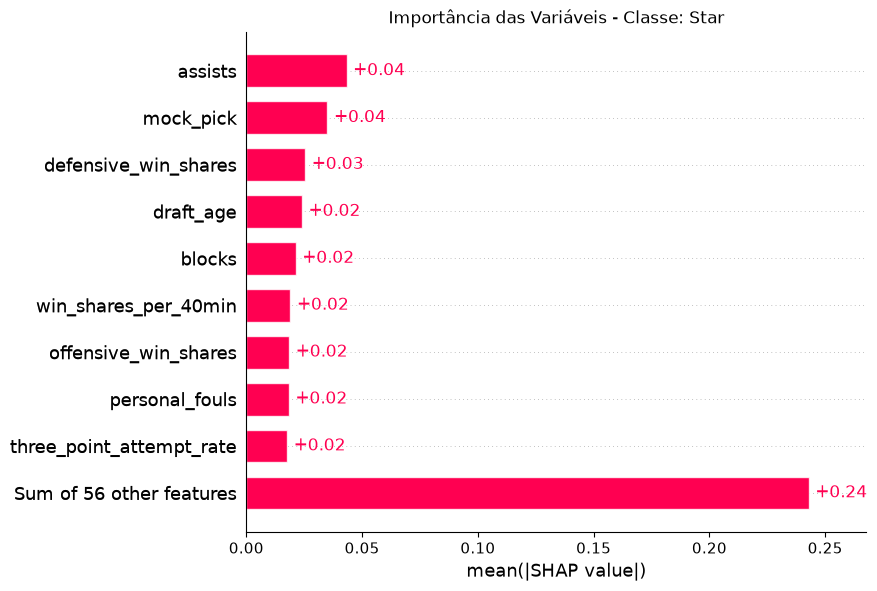

In [62]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP Bar Plot para a classe: {nome}")
    
    # Criar a figura
    plt.figure()
    plt.title(f"Importância das Variáveis - Classe: {nome}")
    
    # Gerar o gráfico de barras para a classe i
    # valores_shap[:,:,i] acessa a explicação específica daquela categoria
    shap.plots.bar(valores_shap[:,:,i], show=False)
    
    plt.show()

    


*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

Gerando SHAP beeswarm para a classe: Bust


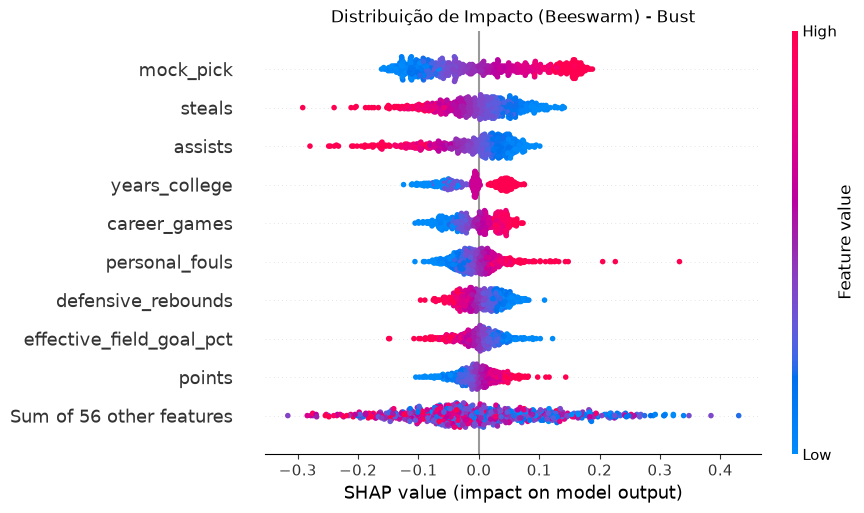

Gerando SHAP beeswarm para a classe: Rotation


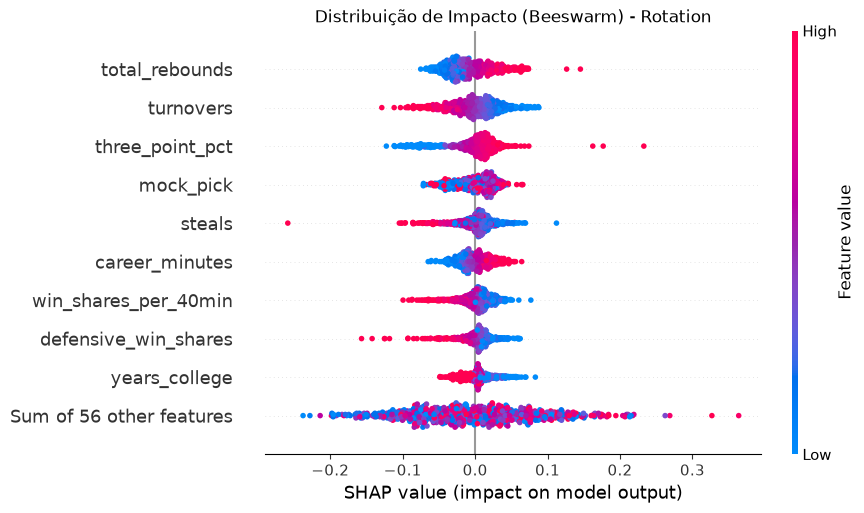

Gerando SHAP beeswarm para a classe: Starter


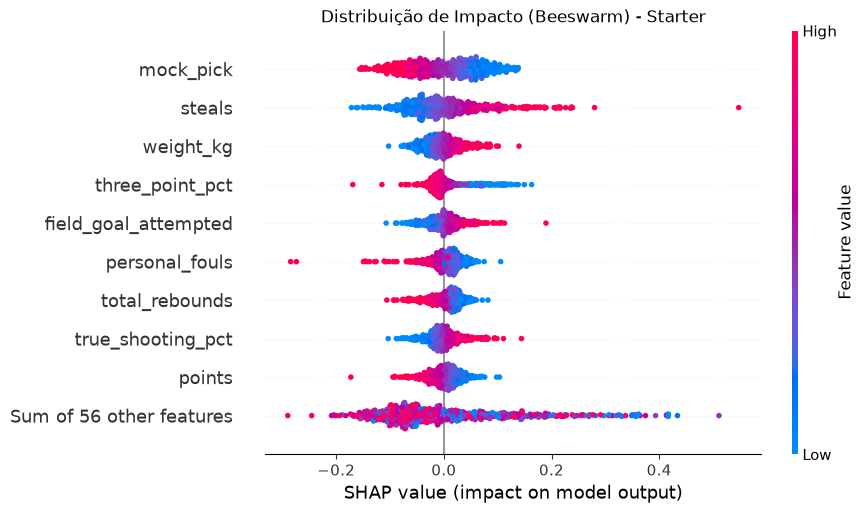

Gerando SHAP beeswarm para a classe: Star


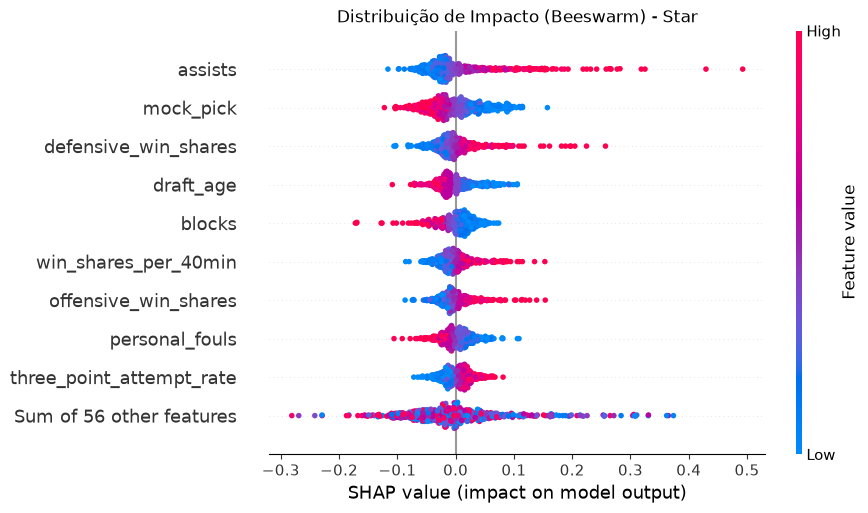

In [63]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP beeswarm para a classe: {nome}")
    
    # Criar a figura
    plt.figure(figsize=(10, 6))
    plt.title(f"Distribuição de Impacto (Beeswarm) - {nome}")
    # Para versões recentes do SHAP, usamos plots.beeswarm
    shap.plots.beeswarm(valores_shap[:, :, i], max_display=10, show=False)
    plt.show()